In [78]:
from copy import copy
from pathlib import Path
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

SEED = 42
EPOCHS = 45
BATCH_SIZE = 128
DEPTH = 32

if torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(device)

mps


In [79]:
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()

        self.stride = stride
        self.channel_padding = (out_channels - in_channels) // 2
        self.branch = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=stride, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
        )

    def forward(self, x):
        correction = self.branch(x)
        shortcut = x

        if self.stride == 2:
            shortcut = x[:, :, ::2, ::2]
            padding = self.channel_padding
            shortcut = F.pad(shortcut, (0, 0, 0, 0, padding, padding))

        return F.relu(correction + shortcut)

In [80]:
def make_stage(in_channels, out_channels, blocks, stride=1):
    layers = [ResidualBlock(in_channels, out_channels, stride)]
    for _ in range(blocks - 1):
        layers.append(ResidualBlock(out_channels, out_channels))
    return nn.Sequential(*layers)


class ResNet(nn.Module):
    def __init__(self, depth=20):
        super().__init__()
        blocks = (depth - 2) // 6

        self.stem = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True),
        )
        self.stages = nn.Sequential(
            make_stage(16, 16, blocks),
            make_stage(16, 32, blocks, stride=2),
            make_stage(32, 64, blocks, stride=2),
        )
        self.classifier = nn.Linear(64, 10)

        for layer in self.modules():
            if isinstance(layer, nn.Conv2d):
                nn.init.kaiming_normal_(layer.weight, mode="fan_in", nonlinearity="relu")
            elif isinstance(layer, nn.BatchNorm2d):
                nn.init.ones_(layer.weight)
                nn.init.zeros_(layer.bias)
        nn.init.normal_(self.classifier.weight, std=0.01)
        nn.init.zeros_(self.classifier.bias)

    def forward(self, x):
        x = self.stem(x)
        x = self.stages(x)
        x = x.mean(dim=(2, 3))
        return self.classifier(x)

##  Dane

In [81]:
data_dir = Path("dane")
previous_cache = Path("../tydzien 1/dane")
if not (data_dir / "cifar-10-batches-py").is_dir() and (previous_cache / "cifar-10-batches-py").is_dir():
    data_dir = previous_cache

train_data = datasets.CIFAR10(data_dir, train=True, download=True)
classes = train_data.classes

split_generator = torch.Generator().manual_seed(SEED)
indices = torch.randperm(len(train_data), generator=split_generator).tolist()
val_indices = indices[:5000]
train_indices = indices[5000:]

mean_array = train_data.data[train_indices].mean(axis=0, dtype=np.float32) / 255.0
mean_image = torch.from_numpy(mean_array).permute(2, 0, 1).contiguous()


def center_image(image):
    image = transforms.functional.to_tensor(image)
    return image - mean_image


train_transform = transforms.Compose([
    center_image,
    transforms.RandomCrop(32, padding=4), 
    transforms.RandomHorizontalFlip(),
])
val_data = copy(train_data)
train_data.transform = train_transform
val_data.transform = center_image

train_loader = DataLoader(
    Subset(train_data, train_indices), batch_size=BATCH_SIZE, shuffle=True,
    generator=torch.Generator().manual_seed(SEED), num_workers=0,
)
val_loader = DataLoader(Subset(val_data, val_indices), batch_size=256, num_workers=0)

print("Images:", len(train_indices), "train,", len(val_indices), "validation")

Images: 45000 train, 5000 validation


##  Ocena modelu

In [82]:
def evaluate(model, loader):
    model.eval()
    total_loss = torch.zeros((), device=device)
    correct = torch.zeros((), dtype=torch.int64, device=device)
    total_images = 0

    with torch.inference_mode():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            scores = model(images)
            loss = F.cross_entropy(scores, labels)

            total_loss += loss * labels.size(0)
            correct += (scores.argmax(dim=1) == labels).sum()
            total_images += labels.size(0)


    average_loss = total_loss.item() / total_images

    accuracy = 100 * correct.item() / total_images
    return average_loss, accuracy

In [83]:
def save_file(data, path):
    temporary_path = path.with_suffix(".tmp")
    torch.save(data, temporary_path)
    temporary_path.replace(path)

In [84]:
def train_model(depth, epochs=45):

    checkpoint_path = Path(f"cosine_resnet{depth}_{epochs}epochs.pt")
    if checkpoint_path.exists():
        print(f"Wczytuję zapisany model: {checkpoint_path}")
        return torch.load(checkpoint_path, map_location="cpu", weights_only=True)

    torch.manual_seed(SEED)
    model = ResNet(depth).to(device)
    torch.manual_seed(SEED)
    train_loader.generator.manual_seed(SEED)

    optimizer = torch.optim.SGD(model.parameters(), lr=0.1)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=epochs,
    )

    history = []
    best_val_loss = float("inf")
    step = 0
    started = time.perf_counter()

    for epoch in range(1, epochs + 1):
        model.train()
        learning_rate = optimizer.param_groups[0]["lr"]

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad(set_to_none=True)

            scores = model(images)
            loss = F.cross_entropy(scores, labels)
            loss.backward()
            optimizer.step()
            step += 1

        val_loss, val_acc = evaluate(model, val_loader)
        history.append({
            "epoch": epoch,
            "val_loss": val_loss,
            "val_acc": val_acc,
            "lr": learning_rate,
        })

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            weights = {}
            for name, value in model.state_dict().items():
                weights[name] = value.detach().cpu()

            saved = {
                "model": weights,
                "depth": depth,
                "epoch": epoch,
                "val_loss": val_loss,
                "val_acc": val_acc,
                "mean_image": mean_image,
                "classes": classes,
                "seed": SEED,
                "history": history,
            }
            save_file(saved, checkpoint_path)

        scheduler.step()
        if epoch == 1 or epoch % 5 == 0 or epoch == epochs:
            print(f"ResNet-{depth} | epoch {epoch}/{epochs} | "
                  f"val loss {val_loss:.4f} | val acc {val_acc:.2f}% | lr {learning_rate:.5g}", flush=True)

    seconds = time.perf_counter() - started
    saved = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    saved["history"] = history
    saved["total_training_steps"] = step
    saved["training_seconds"] = seconds
    save_file(saved, checkpoint_path)
    return saved

## Trening jednego modelu



In [85]:
result = train_model(DEPTH, epochs=EPOCHS)

ResNet-32 | epoch 1/45 | val loss 1.6921 | val acc 36.18% | lr 0.1
ResNet-32 | epoch 5/45 | val loss 1.2045 | val acc 57.38% | lr 0.098063
ResNet-32 | epoch 10/45 | val loss 0.9432 | val acc 69.30% | lr 0.090451
ResNet-32 | epoch 15/45 | val loss 0.8120 | val acc 74.74% | lr 0.07796
ResNet-32 | epoch 20/45 | val loss 0.6253 | val acc 79.90% | lr 0.062096
ResNet-32 | epoch 25/45 | val loss 0.5318 | val acc 82.82% | lr 0.044774
ResNet-32 | epoch 30/45 | val loss 0.4690 | val acc 83.98% | lr 0.028081
ResNet-32 | epoch 35/45 | val loss 0.4662 | val acc 84.98% | lr 0.014033
ResNet-32 | epoch 40/45 | val loss 0.4271 | val acc 86.38% | lr 0.0043227
ResNet-32 | epoch 45/45 | val loss 0.4233 | val acc 86.64% | lr 0.0001218


## Wyniki treningu


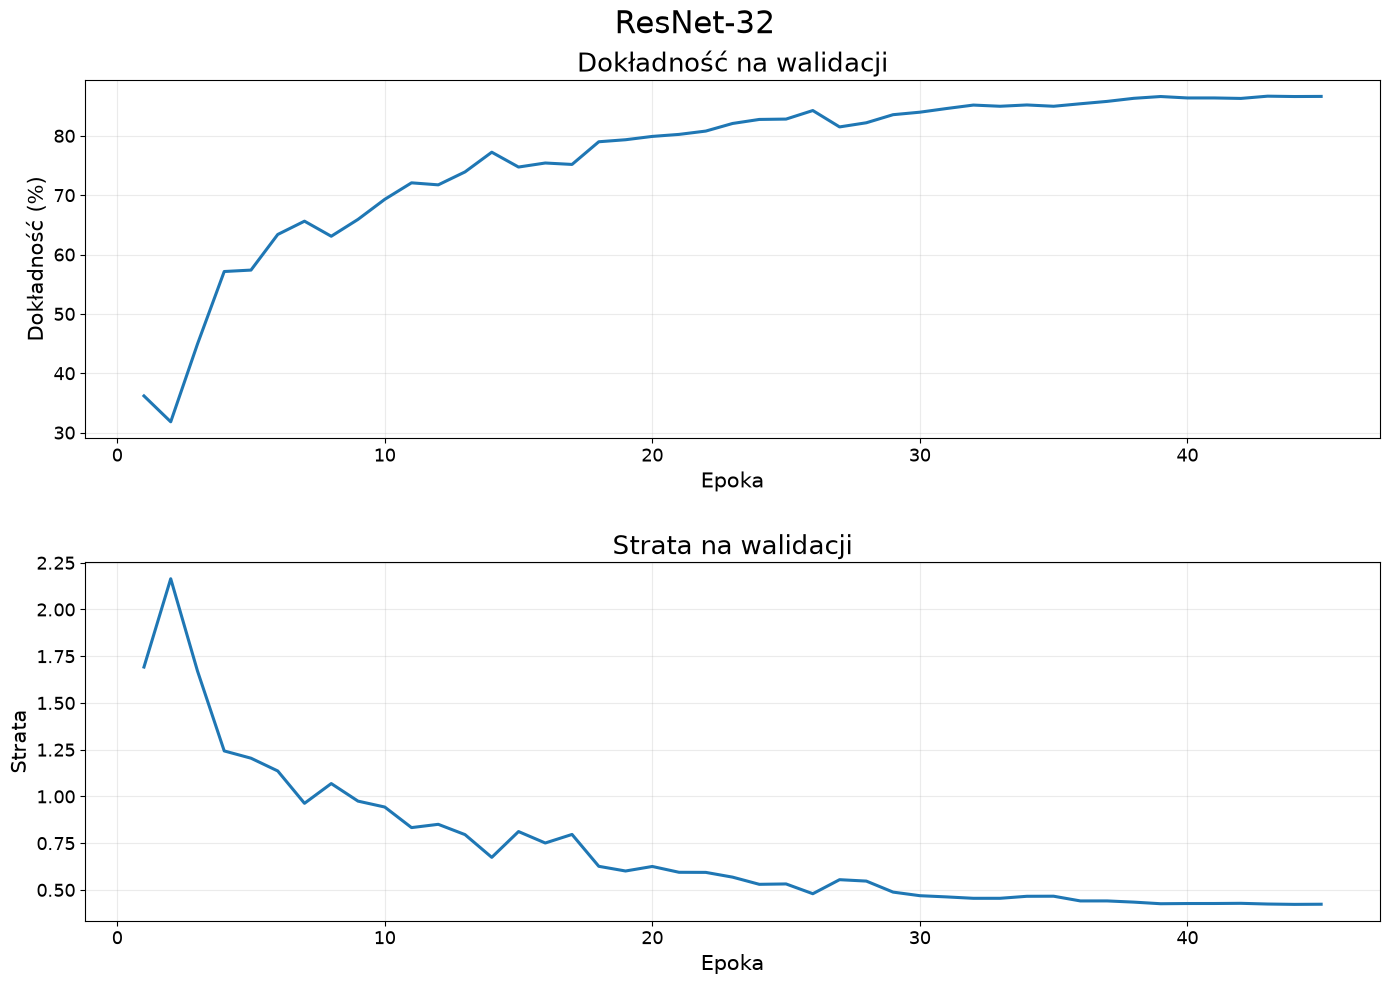

Najlepsza epoka: 44
Strata walidacyjna: 0.4225
Dokładność walidacyjna: 86.62%
Czas treningu: 10.6 min


In [86]:
epochs = []
accuracy = []
loss = []

for row in result["history"]:
    epochs.append(row["epoch"])
    accuracy.append(row["val_acc"])
    loss.append(row["val_loss"])

fig, axes = plt.subplots(2, 1, figsize=(14, 10))
fig.suptitle(f"ResNet-{result['depth']}", fontsize=22)

axes[0].plot(epochs, accuracy, linewidth=2.2)
axes[0].set(xlabel="Epoka", ylabel="Dokładność (%)", title="Dokładność na walidacji")
axes[1].plot(epochs, loss, linewidth=2.2)
axes[1].set(xlabel="Epoka", ylabel="Strata", title="Strata na walidacji")

for ax in axes:
    ax.title.set_fontsize(19)
    ax.xaxis.label.set_size(15)
    ax.yaxis.label.set_size(15)
    ax.tick_params(labelsize=13)
    ax.grid(alpha=0.25)

fig.tight_layout(h_pad=3)
fig.savefig(f"cosine_resnet{result['depth']}_training.png", dpi=180, bbox_inches="tight")
plt.show()

print(f"Najlepsza epoka: {result['epoch']}")
print(f"Strata walidacyjna: {result['val_loss']:.4f}")
print(f"Dokładność walidacyjna: {result['val_acc']:.2f}%")
print(f"Czas treningu: {result['training_seconds'] / 60:.1f} min")


## Przykłady rozpoznań


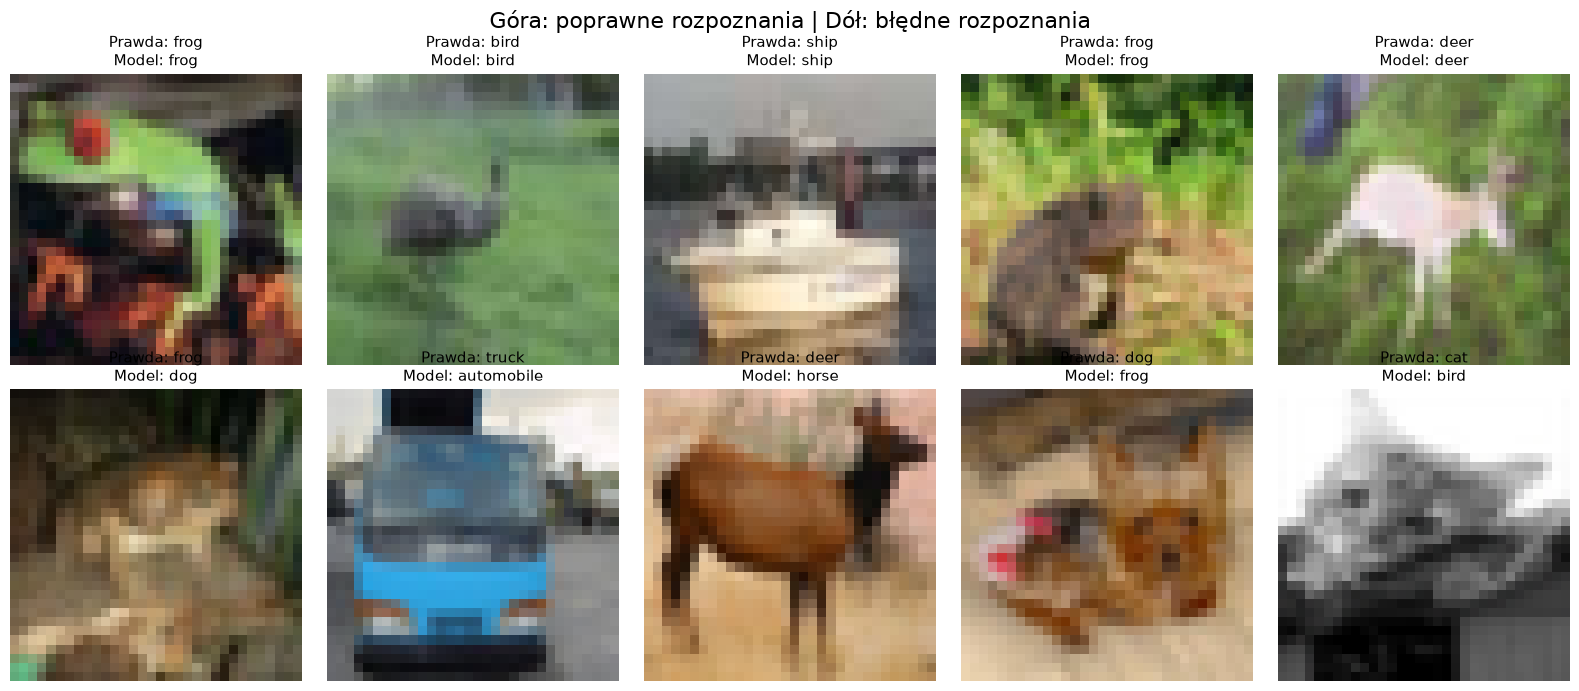

In [87]:
mean_image = result["mean_image"]
classes = result["classes"]
model = ResNet(result["depth"]).to(device)
model.load_state_dict(result["model"])
model.eval()

fig, axes = plt.subplots(2, 5, figsize=(16, 7))
counts = [0, 0]
for ax in axes.flat:
    ax.axis("off")

with torch.inference_mode():
    for images, labels in val_loader:
        predictions = model(images.to(device)).argmax(dim=1).cpu()
        for image, label, prediction in zip(images, labels, predictions):
            if label == prediction:
                row = 0
            else:
                row = 1

            if counts[row] < 5:
                ax = axes[row, counts[row]]
                picture = (image + mean_image).permute(1, 2, 0).clamp(0, 1)
                ax.imshow(picture)
                ax.set_title(
                    f"Prawda: {classes[label.item()]}\nModel: {classes[prediction.item()]}",
                    fontsize=11,
                )
                counts[row] += 1

            if counts == [5, 5]:
                break
        if counts == [5, 5]:
            break

fig.suptitle("Góra: poprawne rozpoznania | Dół: błędne rozpoznania", fontsize=16)
fig.tight_layout()
plt.show()
